# Intro to Machine Learning; Linear Regression Models

In [1]:
import pandas as pd

import numpy as np

## Music Challenge

Which popular songs from the past will be recognized by future generations, and which will fade into obscurity? The website [The Pudding](https://pudding.cool/) conducts the [Music Challenge](https://pudding.cool/2020/04/music-challenge/) where they ask thousands of people whether they recognize hit songs from the past. We'll look at some of the [data](https://github.com/the-pudding/song-decay-clean/tree/master/src/assets/data) related to the article ["Defining the 90s Music Canon"](https://pudding.cool/2020/07/song-decay/).

The data set at https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv contains 344 songs released in the 1990s. For each song, the proportion of survey respondents who recognized the song is recorded, for both Millennial respondents and Gen Z respondents. Our goal will be to use linear regression to **predict the Gen Z recognition**.

We will try several different linear regression models. Save each of your models with a different name because you will compare them at the end.



0. Read in the data and describe the Gen Z recognition variable.

In [2]:
url = "https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv"
songs = pd.read_csv(url)

songs.head()

,artist_song,mean_millennial_recognition,mean_gen_z_recognition
0,2 Pac|||California Love,0.517602,0.268378
1,2Pac|||How Do U Want It,0.209632,0.062439
2,702|||Where My Girls At?,0.553481,0.244176
3,Ace Of Base|||All That She Wants,0.830967,0.540097
4,Ace Of Base|||Don't Turn Around,0.623149,0.372787


In [3]:
songs["mean_gen_z_recognition"].describe()

count    344.000000
mean       0.235506
std        0.210541
min        0.019483
25%        0.095589
50%        0.155398
75%        0.303051
max        0.963497
Name: mean_gen_z_recognition, dtype: float64

1. Use scikit-learn to fit a linear regression model for predicting Gen Z recognition from Millennial recognition.

In [4]:
from sklearn.linear_model import LinearRegression

X = songs[["mean_millennial_recognition"]]
y = songs["mean_gen_z_recognition"]

millennial_model = LinearRegression()
millennial_model.fit(X, y)

print("Intercept:", millennial_model.intercept_)
print("Coefficient:", millennial_model.coef_[0])

Intercept: -0.04814972198183062
Coefficient: 0.7067311793153613


2. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

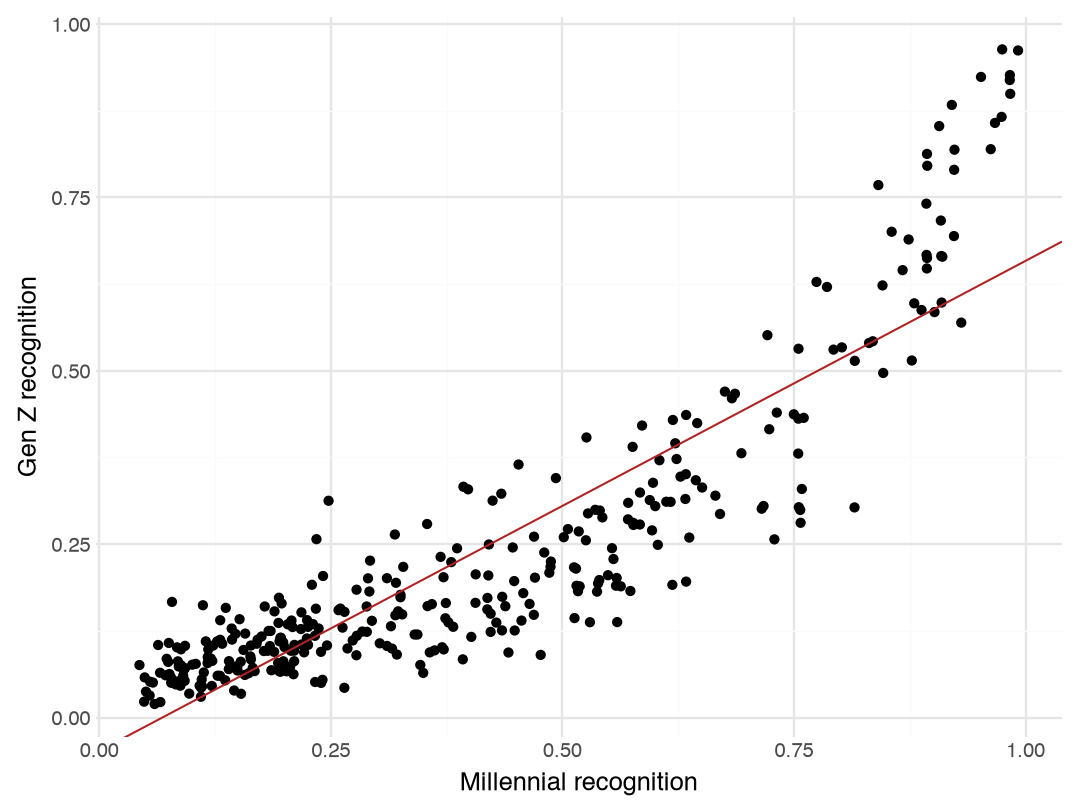

In [5]:
from plotnine import ggplot, aes, geom_point, geom_abline, labs, theme_minimal

(ggplot(
    songs,
    aes(x="mean_millennial_recognition", y="mean_gen_z_recognition")
)
 + geom_point()
 + geom_abline(
     intercept=millennial_model.intercept_,
     slope=millennial_model.coef_[0],
     color="firebrick"
 )
 + labs(
     x="Millennial recognition",
     y="Gen Z recognition"
 )
 + theme_minimal())

3. Explain why you might want to consider taking a log of Gen Z recognition. Then use scikit-learn to fit a linear regression model for predicting log of Gen Z recognition from Millennial recognition.

In [6]:
songs["log_gen_z_recognition"] = np.log(songs["mean_gen_z_recognition"])

X_log = songs[["mean_millennial_recognition"]]
y_log = songs["log_gen_z_recognition"]

log_model = LinearRegression()
log_model.fit(X_log, y_log)

print("Intercept:", log_model.intercept_)
print("Coefficient:", log_model.coef_[0])

Intercept: -2.9082912239452847
Coefficient: 2.7991680362225226


4. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

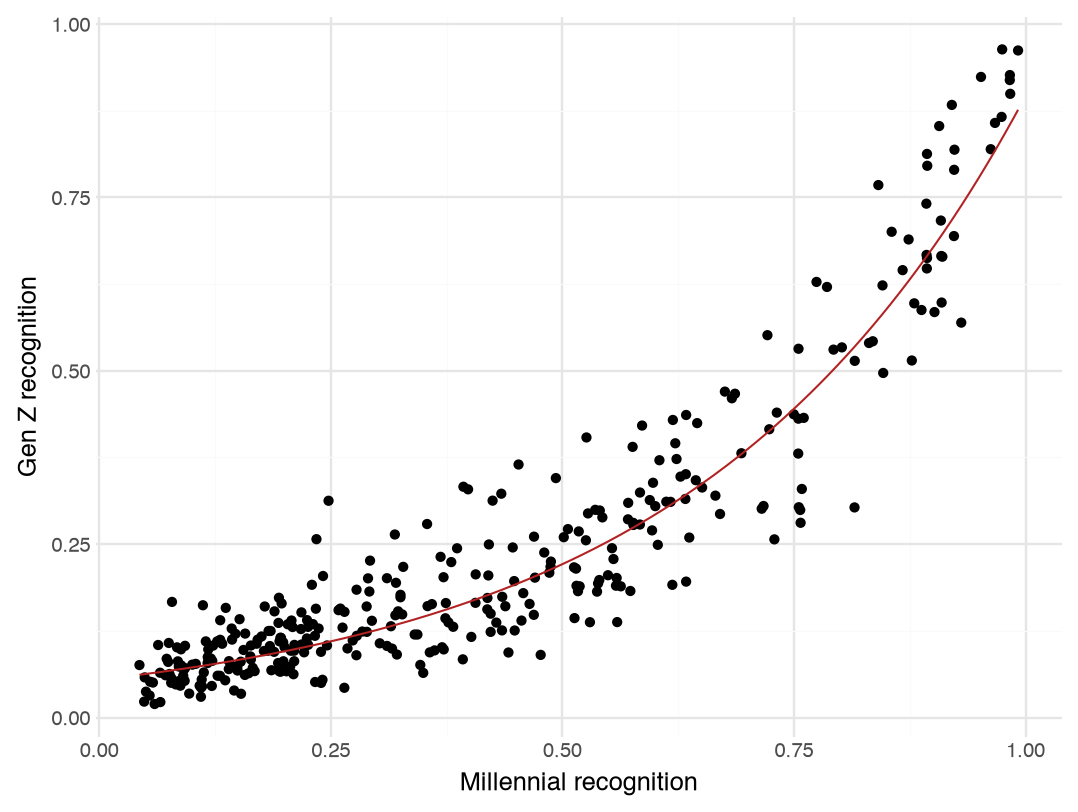

In [7]:
from plotnine import ggplot, aes, geom_point, geom_line, labs, theme_minimal

x_grid = pd.DataFrame({
    "mean_millennial_recognition": np.linspace(
        songs["mean_millennial_recognition"].min(),
        songs["mean_millennial_recognition"].max(),
        200
    )
})

predictions = x_grid.copy()
predictions["predicted_gen_z_recognition"] = np.exp(log_model.predict(x_grid))

(ggplot(
    songs,
    aes(x="mean_millennial_recognition", y="mean_gen_z_recognition")
)
 + geom_point()
 + geom_line(
     data=predictions,
     mapping=aes(
         x="mean_millennial_recognition",
         y="predicted_gen_z_recognition"
     ),
     inherit_aes=False,
     color="firebrick"
 )
 + labs(
     x="Millennial recognition",
     y="Gen Z recognition"
 )
 + theme_minimal())

5. Now we'll try a polynomial model for predicting Gen Z recognition from Millennial recognition. Use scikit-learn to fit a model with two features: Millennial recognition and its square.

In [8]:
songs["millennial_recognition_squared"] = (
    songs["mean_millennial_recognition"] ** 2
)

X_square = songs[
    ["mean_millennial_recognition", "millennial_recognition_squared"]
]
y = songs["mean_gen_z_recognition"]

square_model = LinearRegression()
square_model.fit(X_square, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-0.27, 1.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['mean_millennial_recognition','millennial_recognition_squared']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.1085
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,2


In [9]:
square_model.coef_, square_model.intercept_

(array([-0.27263527,  1.02072241]), np.float64(0.10851294576257645))

6. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model.

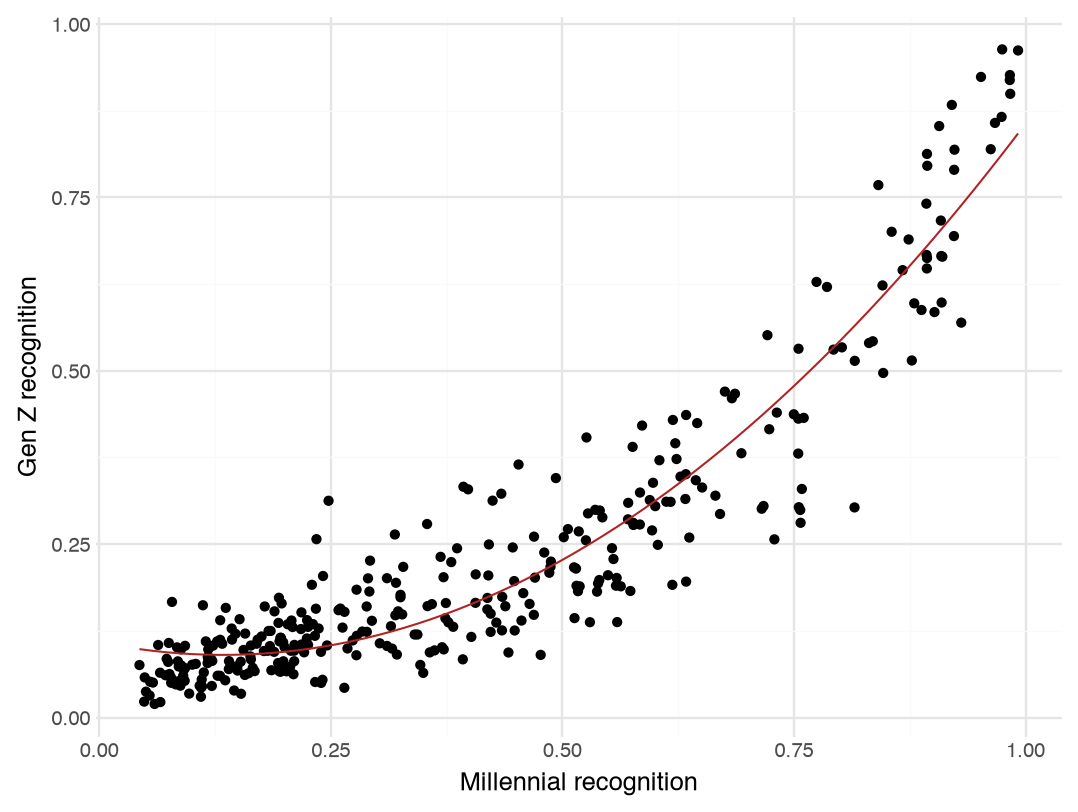

In [10]:
from plotnine import ggplot, aes, geom_point, geom_line, labs, theme_minimal

x_grid = pd.DataFrame({
    "mean_millennial_recognition": np.linspace(
        songs["mean_millennial_recognition"].min(),
        songs["mean_millennial_recognition"].max(),
        200
    )
})
x_grid["millennial_recognition_squared"] = (
    x_grid["mean_millennial_recognition"] ** 2
)

predictions = x_grid.copy()
predictions["predicted_gen_z_recognition"] = square_model.predict(x_grid)

(ggplot(
    songs,
    aes(x="mean_millennial_recognition", y="mean_gen_z_recognition")
)
 + geom_point()
 + geom_line(
     data=predictions,
     mapping=aes(
         x="mean_millennial_recognition",
         y="predicted_gen_z_recognition"
     ),
     inherit_aes=False,
     color="firebrick"
 )
 + labs(
     x="Millennial recognition",
     y="Gen Z recognition"
 )
 + theme_minimal())

7. Choose one of your favorite songs that is in the data set. Use each model to predict the Gen Z recognition for the song. Which model gives the best prediction?

In [11]:
song_choice = "My Heart Will Go On"

song = songs[
    songs["artist_song"].str.contains(song_choice, case=False, na=False)
].iloc[0]

x_value = song["mean_millennial_recognition"]
song_input = pd.DataFrame({
    "mean_millennial_recognition": [x_value],
    "millennial_recognition_squared": [x_value ** 2]
})

actual = song["mean_gen_z_recognition"]

predictions = pd.DataFrame({
    "model": ["linear", "log", "polynomial"],
    "predicted_gen_z_recognition": [
        millennial_model.predict(
            song_input[["mean_millennial_recognition"]]
        )[0],
        np.exp(log_model.predict(
            song_input[["mean_millennial_recognition"]]
        )[0]),
        square_model.predict(song_input)[0]
    ]
})

predictions["actual_gen_z_recognition"] = actual
predictions["absolute_error"] = abs(
    predictions["predicted_gen_z_recognition"] - actual
)

predictions

,model,predicted_gen_z_recognition,actual_gen_z_recognition,absolute_error
0,linear,0.640683,0.963497,0.322814
1,log,0.835259,0.963497,0.128238
2,polynomial,0.812459,0.963497,0.151038


8. The song "Smells Like Teen Spirit" by Nirvana is inexplicably not included in the data set. Suppose the Millenial recognition of this song is 0.7. Use each model to predict the Gen Z recognition for this song. Which model gives the best prediction?

In [12]:
new_song = pd.DataFrame({
    "mean_millennial_recognition": [0.7]
})
new_song["millennial_recognition_squared"] = (
    new_song["mean_millennial_recognition"] ** 2
)

predictions = pd.DataFrame({
    "model": ["linear", "log", "polynomial"],
    "predicted_gen_z_recognition": [
        millennial_model.predict(
            new_song[["mean_millennial_recognition"]]
        )[0],
        np.exp(log_model.predict(
            new_song[["mean_millennial_recognition"]]
        )[0]),
        square_model.predict(new_song)[0]
    ]
})

predictions

,model,predicted_gen_z_recognition
0,linear,0.446562
1,log,0.387177
2,polynomial,0.417822


## Categorical Predictors (FEV data)

Do non-smokers have better lungs than smokers? One measure of lung function is forced expiratory volume (FEV), the amount of air (in liters) an individual can exhale in the first second of forceful breath.  Larger values of FEV are indicative of better functioning lungs. In a study, FEV was measured for a group of 654 subjects, along with whether or not they smoked and other variables.

In [13]:
df_fev = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/FEV.csv")

df_fev

,ID,Smoking status,FEV,Height,Age (months)
0,201,non-smoker,2.884,69.0,132
1,202,non-smoker,2.328,64.0,120
2,301,non-smoker,1.708,57.0,108
3,341,non-smoker,3.381,63.0,172
4,351,non-smoker,2.170,58.0,130
...,...,...,...,...,...
649,83841,non-smoker,2.115,50.0,58
650,83901,non-smoker,2.328,60.0,98
651,83951,smoker,3.069,65.0,130
652,83952,non-smoker,1.495,57.0,85


1\. First fit a regression model with a single predictor: Smoking status. Since this variable is categorical you need to "dummify" it before fitting the model.

In [14]:
from sklearn.linear_model import LinearRegression

X_smoke = pd.get_dummies(
    df_fev[["Smoking status"]],
    drop_first=True
).astype(int)

y_fev = df_fev["FEV"]

smoke_model = LinearRegression()
smoke_model.fit(X_smoke, y_fev)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.71]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Smoking status_smoker']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.566
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


2\. What are the predictions from this model? How could we have known that those would be the predictions?

In [15]:
smoke_levels = pd.DataFrame(
    [[0], [1]],
    columns=X_smoke.columns
)

pd.Series(
    smoke_model.predict(smoke_levels),
    index=["non-smoker", "smoker"]
)

non-smoker    2.566143
smoker        3.276862
dtype: float64

3\. Look at the results for the previous parts. What do you notice? Is this what you expected? Remember: larger FEV means better lungs - who tends to have larger FEV, smokers or non-smokers?

The model shows that smokers tend to have higher average FEV than non-smokers, which may seem surprising because higher FEV indicates better lung function. This simple model only compares the two groups’ averages; it does not account for age or height. If the smokers in the study tend to be older or taller, that could explain their higher FEV. So we shouldn’t conclude from this model alone that smoking improves lung function.

4\. Suggest some explanations for why smokers tend to have *higher* FEV than non-smokers?

Smokers in this sample may be older and taller than non-smokers. FEV tends to increase as children grow, so age and height could explain the higher average FEV among smokers. The model only compared smoking groups and did not account for those differences, so this result does not mean smoking improves lung function.

5\. Fit a linear regression model with two predictors: smoking status and Age (and no interaction).

In [16]:
from sklearn.linear_model import LinearRegression

df_fev["Smoker"] = (
    df_fev["Smoking status"].str.lower() == "smoker"
).astype(int)

X_additive = df_fev[["Smoker", "Age (months)"]]
y_fev = df_fev["FEV"]

age_smoke_model = LinearRegression()
age_smoke_model.fit(X_additive, y_fev)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-0.22, 0.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Smoker','Age (months)']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.3681
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,2


6\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

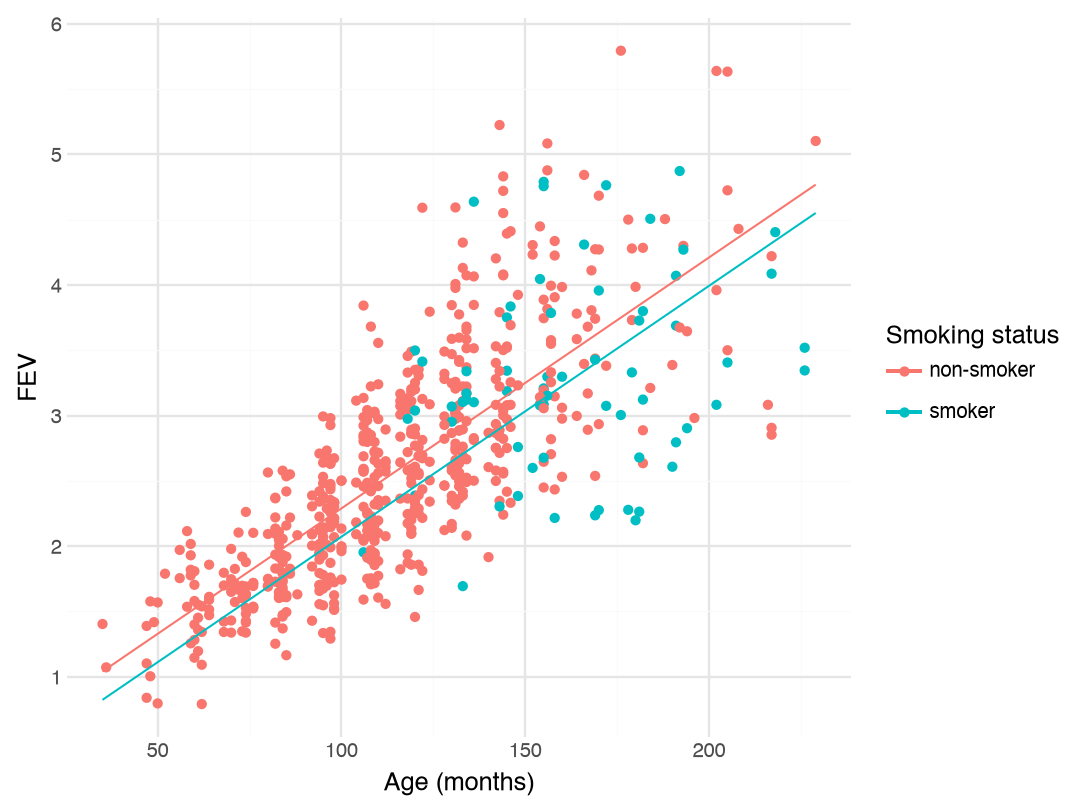

In [17]:
from plotnine import ggplot, aes, geom_point, geom_line, labs, theme_minimal

age_values = np.linspace(
    df_fev["Age (months)"].min(),
    df_fev["Age (months)"].max(),
    100
)

plot_predictions = pd.DataFrame({
    "Age (months)": np.tile(age_values, 2),
    "Smoking status": (
        ["non-smoker"] * len(age_values)
        + ["smoker"] * len(age_values)
    ),
    "Smoker": [0] * len(age_values) + [1] * len(age_values)
})

plot_predictions["predicted_FEV"] = age_smoke_model.predict(
    plot_predictions[["Smoker", "Age (months)"]]
)

(ggplot(
    df_fev,
    aes(x="Age (months)", y="FEV", color="Smoking status")
)
 + geom_point()
 + geom_line(
     data=plot_predictions,
     mapping=aes(
         x="Age (months)",
         y="predicted_FEV",
         color="Smoking status"
     ),
     inherit_aes=False
 )
 + labs(x="Age (months)", y="FEV")
 + theme_minimal())

7\. Fit a linear regression model with predictors smoking status, Age, and their interaction.

In [18]:
X_interaction = pd.DataFrame({
    "Smoker": df_fev["Smoker"],
    "Age (months)": df_fev["Age (months)"],
    "Smoker_x_Age": df_fev["Smoker"] * df_fev["Age (months)"]
})

interaction_model = LinearRegression()
interaction_model.fit(X_interaction, y_fev)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 1.87, 0.02,-0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Smoker','Age (months)','Smoker_x_Age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.2595
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3


8\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

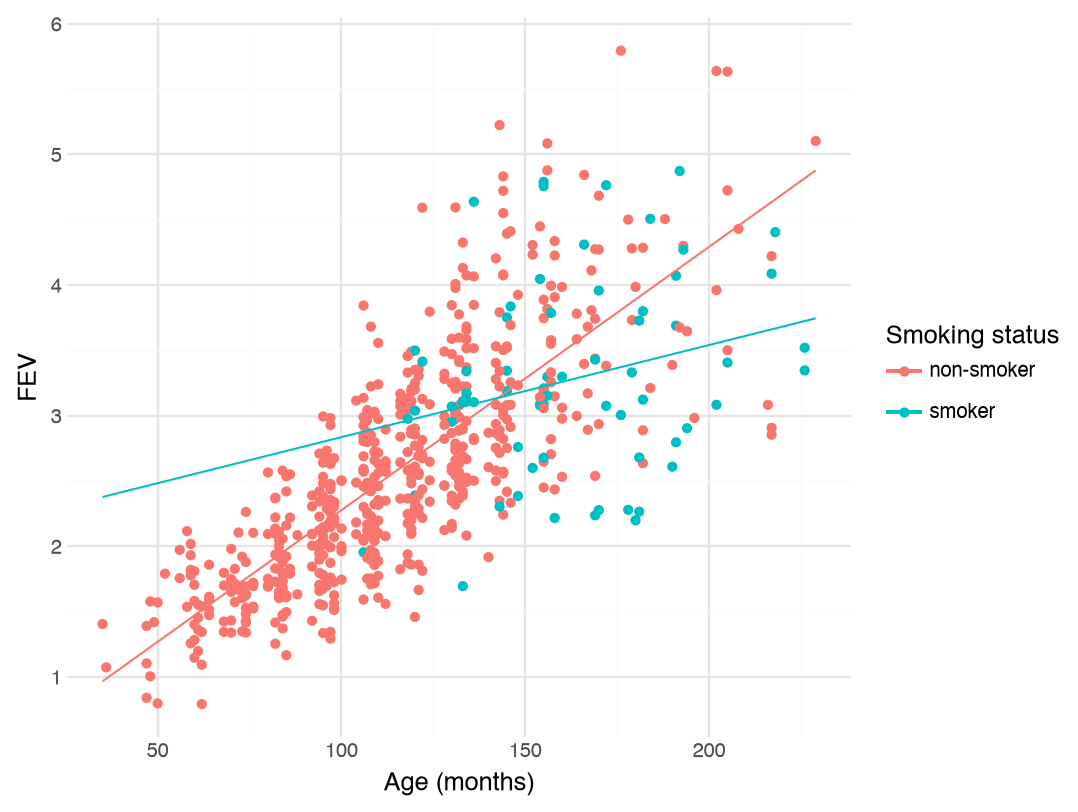

In [19]:
from plotnine import ggplot, aes, geom_point, geom_line, labs, theme_minimal

age_values = np.linspace(
    df_fev["Age (months)"].min(),
    df_fev["Age (months)"].max(),
    100
)

plot_predictions = pd.DataFrame({
    "Age (months)": np.tile(age_values, 2),
    "Smoking status": (
        ["non-smoker"] * len(age_values)
        + ["smoker"] * len(age_values)
    ),
    "Smoker": [0] * len(age_values) + [1] * len(age_values)
})

plot_predictions["Smoker_x_Age"] = (
    plot_predictions["Smoker"] * plot_predictions["Age (months)"]
)

plot_predictions["predicted_FEV"] = interaction_model.predict(
    plot_predictions[["Smoker", "Age (months)", "Smoker_x_Age"]]
)

(ggplot(
    df_fev,
    aes(x="Age (months)", y="FEV", color="Smoking status")
)
 + geom_point()
 + geom_line(
     data=plot_predictions,
     mapping=aes(
         x="Age (months)",
         y="predicted_FEV",
         color="Smoking status"
     ),
     inherit_aes=False
 )
 + labs(x="Age (months)", y="FEV")
 + theme_minimal())

9\. Compare the models. Which do you think is "best"? Why? How could you investigate?

The first model compares smokers and non-smokers without accounting for age. The second model includes age and smoking status, and assumes age affects FEV the same way in both groups. The interaction model allows the relationship between age and FEV to differ by smoking status. I would compare the models’ prediction errors on test data, or use cross-validation. I’d choose the interaction model if it meaningfully lowers test error; otherwise, the simpler model may be preferable.